
# Applied Machine Learning Lab Assignment - Part 2 - Unsupervised-Learning-Algorithms

## Question 2: Clustering, Ensemble Learning and PCA
## Question 3: Performance Analysis

# Questions Given:
Q2  a. Computing distances and similarities, implementation and analysis of K
    means clustering and Hierarchical clustering, dendrogram construction and 
    linkage methods. 

Q2 b. Through coding, understand how ensemble methods in machine learning 
    work, implementation and analysis of bagging techniques such as Random 
    Forest and boosting algorithms. 

Q2 c. Implementation of Gaussian Mixture Models (GMM) for clustering tasks. 

Q2 d. Implementation and visualization using Principal Component Analysis (PCA).

Q3 Analyse the performance of the different models developed in question (1) and (2) 
using appropriate metrices.

### Objectives(Questions to Implement)
1. Compute distances and similarities between observations.
2. Implement K-means and Hierarchical Clustering.
3. Construct dendrograms and analyze linkage methods.
4. Implement ensemble learning using Bagging, Random Forest and Boosting.
5. Implement Gaussian Mixture Models for clustering.
6. Apply PCA for dimensionality reduction and visualization.
7. Analyze model performance using appropriate evaluation metrics.



## Introduction

This experiment explores unsupervised learning, ensemble learning and dimensionality reduction techniques.

K-means and Hierarchical Clustering identify groups of similar observations using distance measures. Dendrograms visualize hierarchical relationships between clusters, while linkage methods determine how clusters are merged.

Ensemble learning combines multiple estimators to improve predictive performance. Bagging and Random Forest reduce variance through model aggregation, whereas Boosting builds models sequentially to improve predictions.

Gaussian Mixture Models represent data using a mixture of probability distributions, allowing probabilistic cluster assignments. Principal Component Analysis transforms the original features into a smaller set of components while retaining as much variance as possible.

The implemented models are evaluated using suitable metrics and visualizations.


In [1]:
#Import necessary libraries that are required for the assignment

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris, load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA

from sklearn.metrics import (
    pairwise_distances,
    silhouette_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from sklearn.ensemble import (
    BaggingClassifier,
    RandomForestClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier
)

from sklearn.tree import DecisionTreeClassifier
from scipy.cluster.hierarchy import linkage, dendrogram

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("All libraries imported successfully.")


All libraries imported successfully.



## Dataset Preparation

The Iris dataset is used for distance calculations, clustering and PCA. It contains 150 observations, four numerical features and three flower species.

The Breast Cancer Wisconsin dataset is used for ensemble classification. It contains numerical features and labels identifying malignant and benign cases.

Feature standardization is applied to the Iris dataset before distance-based clustering and PCA. The classification dataset is divided into training and testing subsets to evaluate ensemble models on unseen data.

The Iris species labels are not used to train the clustering algorithms.


In [ ]:
# Iris dataset for clustering and PCA
iris = load_iris(as_frame=True)

X_iris = iris.data
y_iris = iris.target

#Here we are scaling the iris dataset using StandardScaler to standardize the features by removing the mean and scaling to unit variance. 
#This is important for many machine learning algorithms that are sensitive to the scale of the data.
iris_scaler = StandardScaler()
X_iris_scaled = iris_scaler.fit_transform(X_iris)

# Breast Cancer dataset for ensemble classification
cancer = load_breast_cancer(as_frame=True)

X_cls = cancer.data
y_cls = cancer.target

X_train, X_test, y_train, y_test = train_test_split(
    X_cls,
    y_cls,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y_cls
)

print("Iris dataset:", X_iris.shape)
print("Classification training set:", X_train.shape)
print("Classification test set:", X_test.shape)
print("Datasets loaded successfully.")


Iris dataset: (150, 4)
Classification training set: (455, 30)
Classification test set: (114, 30)
Datasets loaded successfully.



# Q2(a): Distance Measures and Clustering

## 2.1 Aim

To compute distances and similarities between observations and understand their role in clustering algorithms.

## 2.2 Theory

- **Euclidean distance:** Measures straight-line distance between two observations.
- **Manhattan distance:** Calculates the sum of absolute differences between corresponding features.
- **Cosine similarity:** Measures the similarity in direction between two nonzero feature vectors.

Distance measures quantify dissimilarity, whereas similarity measures quantify how closely related two observations are.

## 2.3 Methodology

1. Select observations from the standardized Iris dataset.
2. Calculate Euclidean and Manhattan distance matrices.
3. Calculate cosine similarity.
4. Compare the results.
5. Gain some inference from it

In [3]:
sample = X_iris_scaled[:3]

euclidean_distances = pairwise_distances(
    sample, metric="euclidean"
)

manhattan_distances = pairwise_distances(
    sample, metric="manhattan"
)

cosine_similarity = 1 - pairwise_distances(
    sample, metric="cosine"
)

print("Euclidean Distance Matrix")
display(pd.DataFrame(euclidean_distances).round(3))

print("Manhattan Distance Matrix")
display(pd.DataFrame(manhattan_distances).round(3))

print("Cosine Similarity Matrix")
display(pd.DataFrame(cosine_similarity).round(3))


Euclidean Distance Matrix


,0,1,2
0,0.000,1.176,0.846
1,1.176,0.000,0.523
2,0.846,0.523,0.000


Manhattan Distance Matrix


,0,1,2
0,0.000,1.393,1.232
1,1.393,0.000,0.760
2,1.232,0.760,0.000


Cosine Similarity Matrix


,0,1,2
0,1.000,0.866,0.936
1,0.866,1.000,0.977
2,0.936,0.977,1.000



### Inference

From the matrices, observations 1 and 2 are the closest to each other, with a Euclidean distance of 0.523 and a cosine similarity of 0.977. Observations 0 and 1 are comparatively farther apart, with a Euclidean distance of 1.176 and a cosine similarity of 0.866. The diagonal values are zero for the distance matrices and one for cosine similarity because each observation is compared with itself. Thus, the matrices help us understand how similar or different the observations are, which is useful for clustering.


## Q2(a) — K-means Clustering

## 2.4 K-means Clustering

### Aim
To implement K-means clustering on the Iris dataset and evaluate the clusters using inertia and silhouette scores.

### Theory
K-means is an unsupervised learning algorithm that divides data into a specified number of clusters. Each observation is assigned to the nearest cluster centroid, and the centroids are updated iteratively until the cluster assignments stabilize.

Inertia measures the sum of squared distances between observations and their assigned centroids. The silhouette score measures how well observations fit within their assigned clusters compared with other clusters.

### Procedure
1. Apply K-means for different values of K.
2. Calculate inertia and silhouette scores.
3. Visualize the clusters for K = 3.
4. Compare the results to understand the effect of the number of clusters.


In [4]:
#Implementing KMeans clustering on the scaled iris dataset for different values of k (number of clusters) and evaluating the results using inertia and silhouette score.
kmeans_results = []
kmeans_models = {}

for k in [2, 3, 4, 5]:
    model = KMeans(
        n_clusters=k,
        random_state=RANDOM_STATE,
        n_init=10
    )

    labels = model.fit_predict(X_iris_scaled)

    kmeans_models[k] = model

    kmeans_results.append({
        "K": k,
        "Inertia": model.inertia_,
        "Silhouette Score": silhouette_score(
            X_iris_scaled, labels
        )
    })

kmeans_results_df = pd.DataFrame(kmeans_results)

display(kmeans_results_df.round(3))


,K,Inertia,Silhouette Score
0,2,222.362,0.582
1,3,139.820,0.460
2,4,114.093,0.387
3,5,90.928,0.346


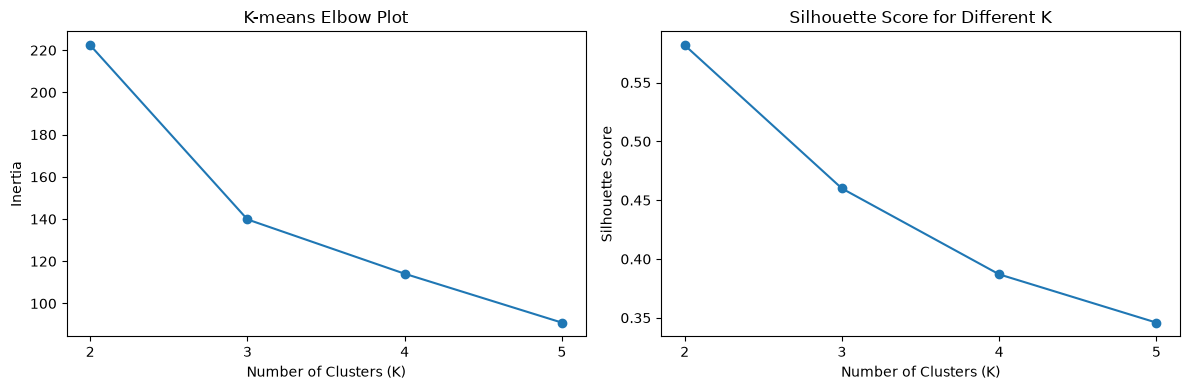

In [ ]:
#Implementation of KMeans clustering results visualization using Elbow Plot and Silhouette Score for different values of K (number of clusters).
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(
    kmeans_results_df["K"],
    kmeans_results_df["Inertia"],
    marker="o"
)
axes[0].set_title("K-means Elbow Plot")
axes[0].set_xlabel("Number of Clusters (K)")
axes[0].set_ylabel("Inertia")
axes[0].set_xticks([2, 3, 4, 5])

axes[1].plot(
    kmeans_results_df["K"],
    kmeans_results_df["Silhouette Score"],
    marker="o"
)
axes[1].set_title("Silhouette Score for Different K")
axes[1].set_xlabel("Number of Clusters (K)")
axes[1].set_ylabel("Silhouette Score")
axes[1].set_xticks([2, 3, 4, 5])

plt.tight_layout()
plt.show()


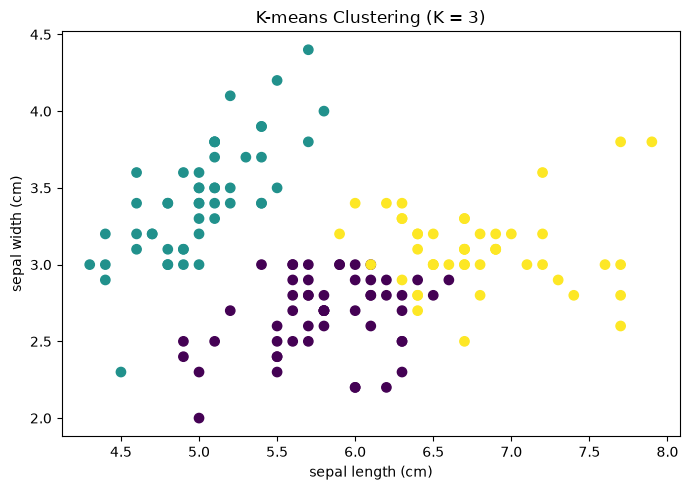

In [ ]:
#Implementing KMeans clustering results visualization using a scatter plot for K=3 clusters on the first two features of the iris dataset.
kmeans_labels = kmeans_models[3].labels_

plt.figure(figsize=(7, 5))

plt.scatter(
    X_iris.iloc[:, 0],
    X_iris.iloc[:, 1],
    c=kmeans_labels,
    s=45
)

plt.xlabel(iris.feature_names[0])
plt.ylabel(iris.feature_names[1])
plt.title("K-means Clustering (K = 3)")
plt.tight_layout()
plt.show()


### Inference

K-means was applied to the Iris dataset using different values of K, from 2 to 5. As K increased, the inertia decreased from 222.362 to 90.928. However, the silhouette score was highest for K = 2 (0.582) and decreased as more clusters were added. The scatter plot for K = 3 shows three groups, with some overlap between them. Therefore, K = 2 gave better-separated clusters in our experiment, while K = 3 can be used when we want to divide the data into three groups.

## Q2(a)

## 2.5 Hierarchical Clustering and Dendrogram

### Aim
To implement Hierarchical Clustering, construct a dendrogram and compare different linkage methods.

### Theory
Hierarchical Clustering groups observations by repeatedly merging nearby clusters. In agglomerative clustering, each observation starts as an individual cluster, and clusters are merged step by step.

A dendrogram is a tree-like diagram that shows the order in which clusters are merged and the distances at which these merges occur.

The main linkage methods are:
- Single linkage: minimum distance between two clusters.
- Complete linkage: maximum distance between two clusters.
- Average linkage: average distance between observations in two clusters.
- Ward linkage: merges clusters to minimize the increase in within-cluster variance.

### Procedure
1. Construct a dendrogram using the standardized Iris data.
2. Apply Agglomerative Clustering with different linkage methods.
3. Compare the resulting clusters using silhouette scores.


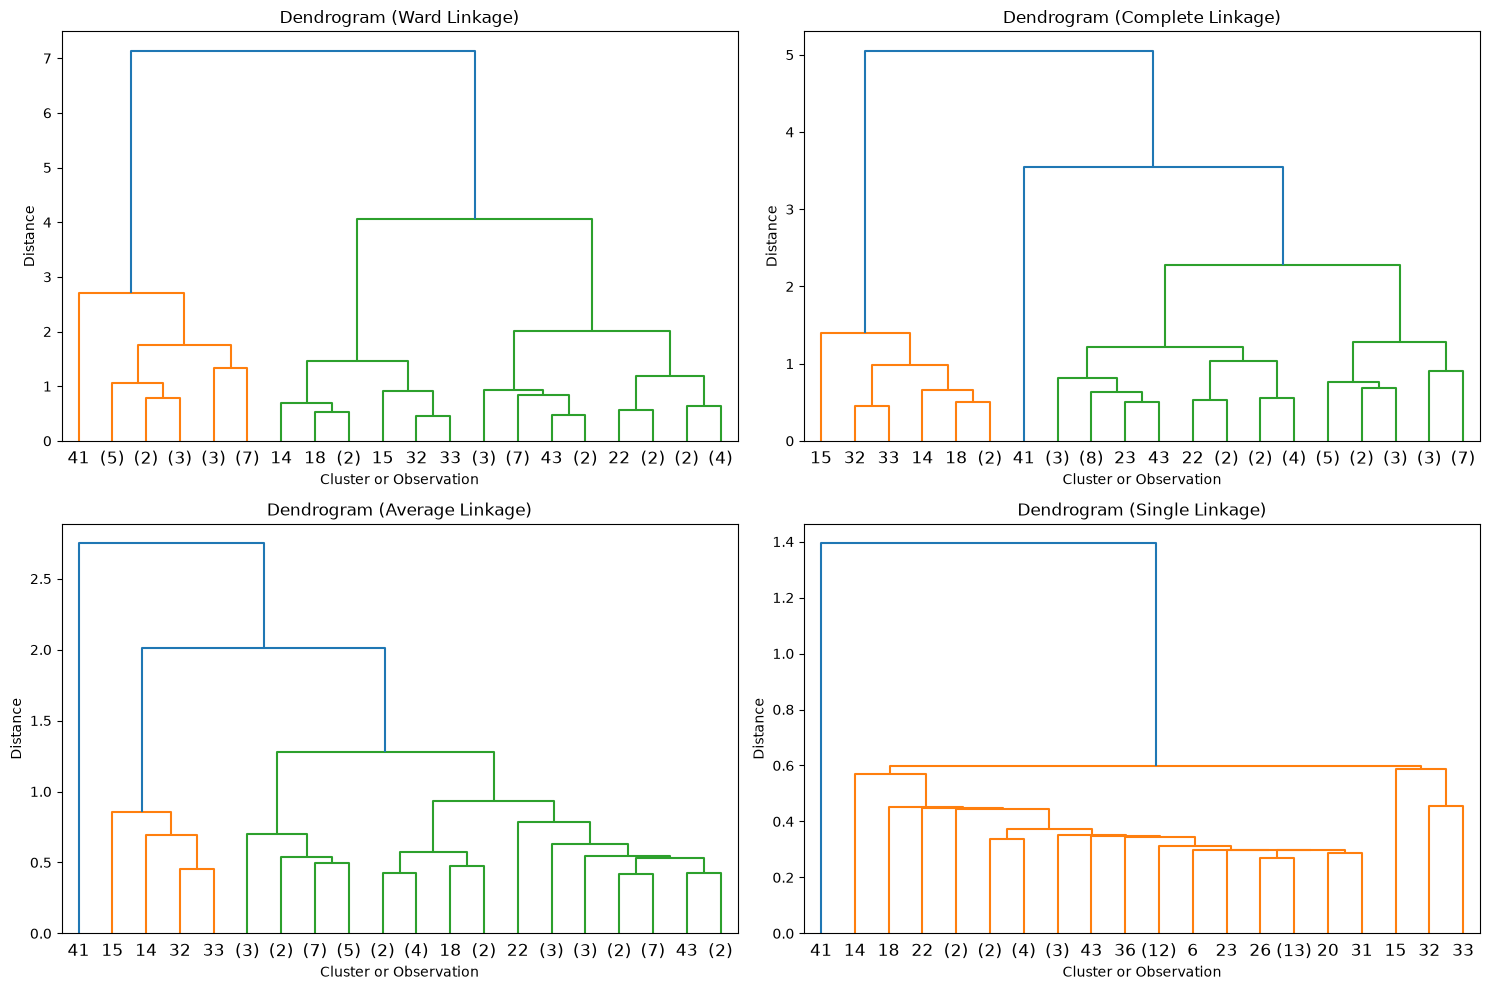

In [ ]:
# In This section, we are implementing Agglomerative Hierarchical Clustering on the scaled iris dataset using different linkage methods.
# Generate dendrograms using different linkage methods

methods = ["ward", "complete", "average", "single"]

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

for method, ax in zip(methods, axes.flatten()):

    linkage_matrix = linkage(
        X_iris_scaled[:50],
        method=method,
        metric="euclidean"
    )

    dendrogram(
        linkage_matrix,
        truncate_mode="lastp",
        p=20,
        show_leaf_counts=True,
        ax=ax
    )

    ax.set_title(f"Dendrogram ({method.capitalize()} Linkage)")
    ax.set_xlabel("Cluster or Observation")
    ax.set_ylabel("Distance")

plt.tight_layout()
plt.show()


In [ ]:
#Here We are implementing hierarchical clustering on the scaled iris dataset using different linkage methods (ward, complete, average, single) 
#and evaluating the results using silhouette score. The results are stored in a DataFrame for comparison.

hierarchical_results = []
hierarchical_models = {}

for method in ["ward", "complete", "average", "single"]:
    model = AgglomerativeClustering(
        n_clusters=3,
        linkage=method
    )

    labels = model.fit_predict(X_iris_scaled)
    hierarchical_models[method] = labels

    hierarchical_results.append({
        "Linkage Method": method,
        "Number of Clusters": 3,
        "Silhouette Score": silhouette_score(
            X_iris_scaled, labels
        )
    })

hierarchical_results_df = pd.DataFrame(
    hierarchical_results
)

display(hierarchical_results_df.round(3))


,Linkage Method,Number of Clusters,Silhouette Score
0,ward,3,0.447
1,complete,3,0.450
2,average,3,0.480
3,single,3,0.505


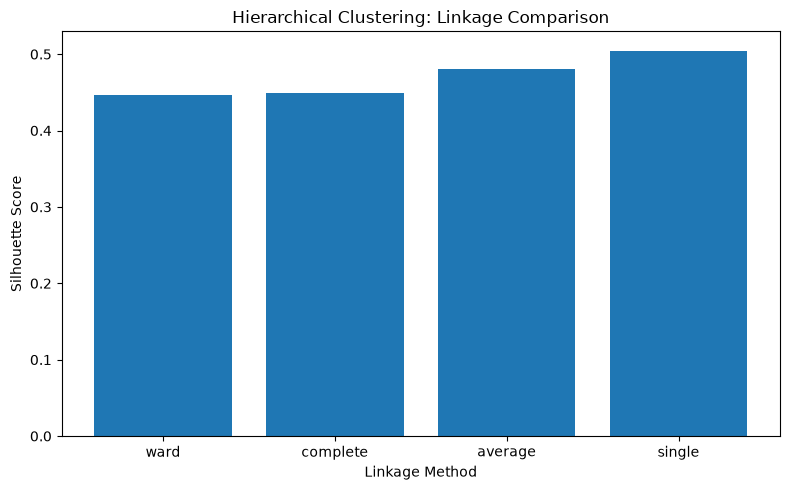

In [10]:
#Here we are visualizing the silhouette scores for different linkage methods used in hierarchical clustering on the scaled iris dataset.
plt.figure(figsize=(8, 5))

plt.bar(
    hierarchical_results_df["Linkage Method"],
    hierarchical_results_df["Silhouette Score"]
)

plt.xlabel("Linkage Method")
plt.ylabel("Silhouette Score")
plt.title("Hierarchical Clustering: Linkage Comparison")
plt.tight_layout()
plt.show()


### Inference

Hierarchical Clustering was performed using four linkage methods: Ward, Complete, Average and Single. Among these, Single Linkage achieved the highest silhouette score of 0.505, followed by Average Linkage at 0.480, Complete Linkage at 0.450 and Ward Linkage at 0.447. This shows that Single Linkage produced the best-separated clusters among the methods tested. The dendrogram illustrates how observations are gradually merged into larger clusters at increasing distances. Overall, the results show that the choice of linkage method affects the clusters formed, even when the number of clusters is kept fixed at three.


## Q2(b): Ensemble Learning — Bagging, Random Forest and Boosting

### Aim
To implement and compare ensemble learning algorithms for classification using the Breast Cancer Wisconsin dataset.

### Theory

Ensemble learning combines multiple machine learning models to improve predictive performance and robustness.

**Bagging (Bootstrap Aggregating):** Multiple models are trained on different bootstrap samples of the training data, and their predictions are combined. This can reduce variance.

**Random Forest:** Random Forest is an ensemble of decision trees trained using bootstrap samples and randomized feature selection. The final prediction is obtained by combining the predictions of individual trees.

**Boosting:** Boosting builds models sequentially, with each new model attempting to improve the existing ensemble.

- **AdaBoost:** Gives more attention to observations misclassified by previous weak learners.
- **Gradient Boosting:** Builds successive models to reduce a loss function using gradient-based updates.

### Methodology
1. Load the Breast Cancer Wisconsin dataset.
2. Train Bagging, Random Forest, AdaBoost and Gradient Boosting classifiers.
3. Evaluate the models on the same test set.
4. Compare their performance using classification metrics and visualizations.


In [12]:
#This section implements ensemble classification models using Bagging, Random Forest, AdaBoost, and Gradient Boosting classifiers. Each model is trained on the breast cancer dataset, 
# and their performance is evaluated using accuracy, precision, recall, F1-score, and ROC-AUC metrics. 
# The results are stored in a DataFrame for comparison.
# This Code uses the Training and Test data (X_train, X_test, y_train, and y_test) variables were already created in the initial part of the notebook setup.

# Q2(b): Implement ensemble classification models

ensemble_models = {
    "Bagging": BaggingClassifier(
        estimator=DecisionTreeClassifier(random_state=RANDOM_STATE),
        n_estimators=100,
        random_state=RANDOM_STATE
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=RANDOM_STATE
    ),

    "AdaBoost": AdaBoostClassifier(
        n_estimators=100,
        random_state=RANDOM_STATE
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=100,
        random_state=RANDOM_STATE
    )
}

ensemble_results = []
ensemble_fitted_models = {}

for name, model in ensemble_models.items():
    model.fit(X_train, y_train)

    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    ensemble_fitted_models[name] = model

    ensemble_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_test, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, probabilities)
    })

ensemble_results_df = pd.DataFrame(ensemble_results)

display(ensemble_results_df.round(3))


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Bagging,0.939,0.945,0.958,0.952,0.993
1,Random Forest,0.956,0.959,0.972,0.966,0.994
2,AdaBoost,0.956,0.947,0.986,0.966,0.982
3,Gradient Boosting,0.956,0.947,0.986,0.966,0.991



### Performance Evaluation

The ensemble classifiers are evaluated using the same test dataset.

- **Accuracy:** Proportion of correctly classified observations.
- **Precision:** Proportion of positive predictions that are correct.
- **Recall:** Proportion of actual positive observations correctly identified.
- **F1-score:** Harmonic mean of precision and recall.
- **ROC-AUC:** Measures the model's ability to distinguish between the two classes across classification thresholds.

In this dataset, class 1 represents benign cases and class 0 represents malignant cases. The default precision and recall calculations treat class 1 as the positive class, so the malignant-class recall should also be examined when interpreting the results.


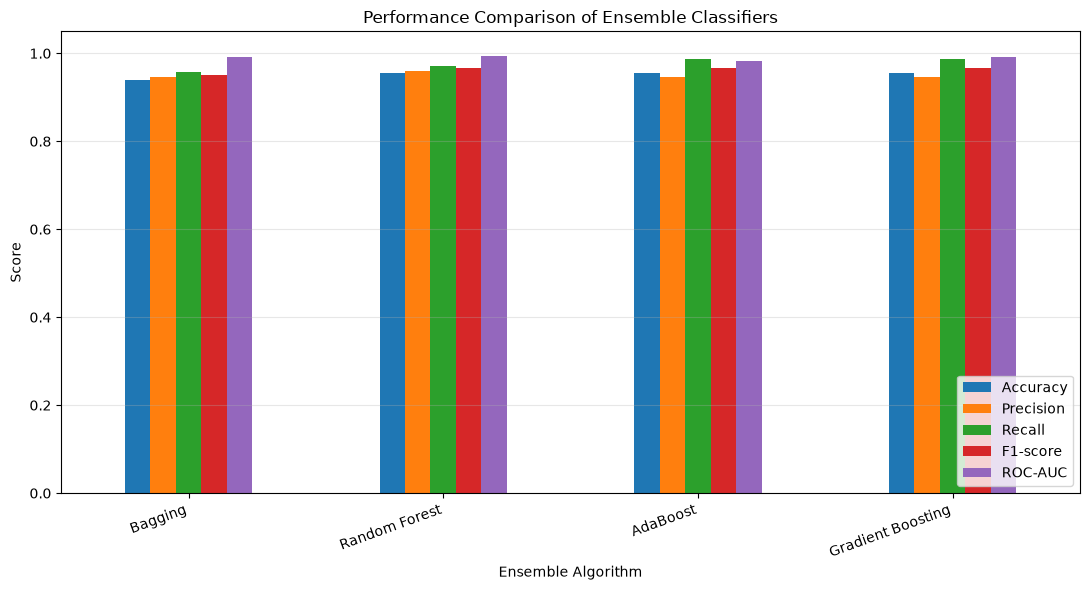

In [13]:

# Compare ensemble classifiers using evaluation metrics

metrics = ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]

ensemble_results_df.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Performance Comparison of Ensemble Classifiers")
plt.ylabel("Score")
plt.xlabel("Ensemble Algorithm")
plt.ylim(0, 1.05)
plt.xticks(rotation=20, ha="right")
plt.legend(loc="lower right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


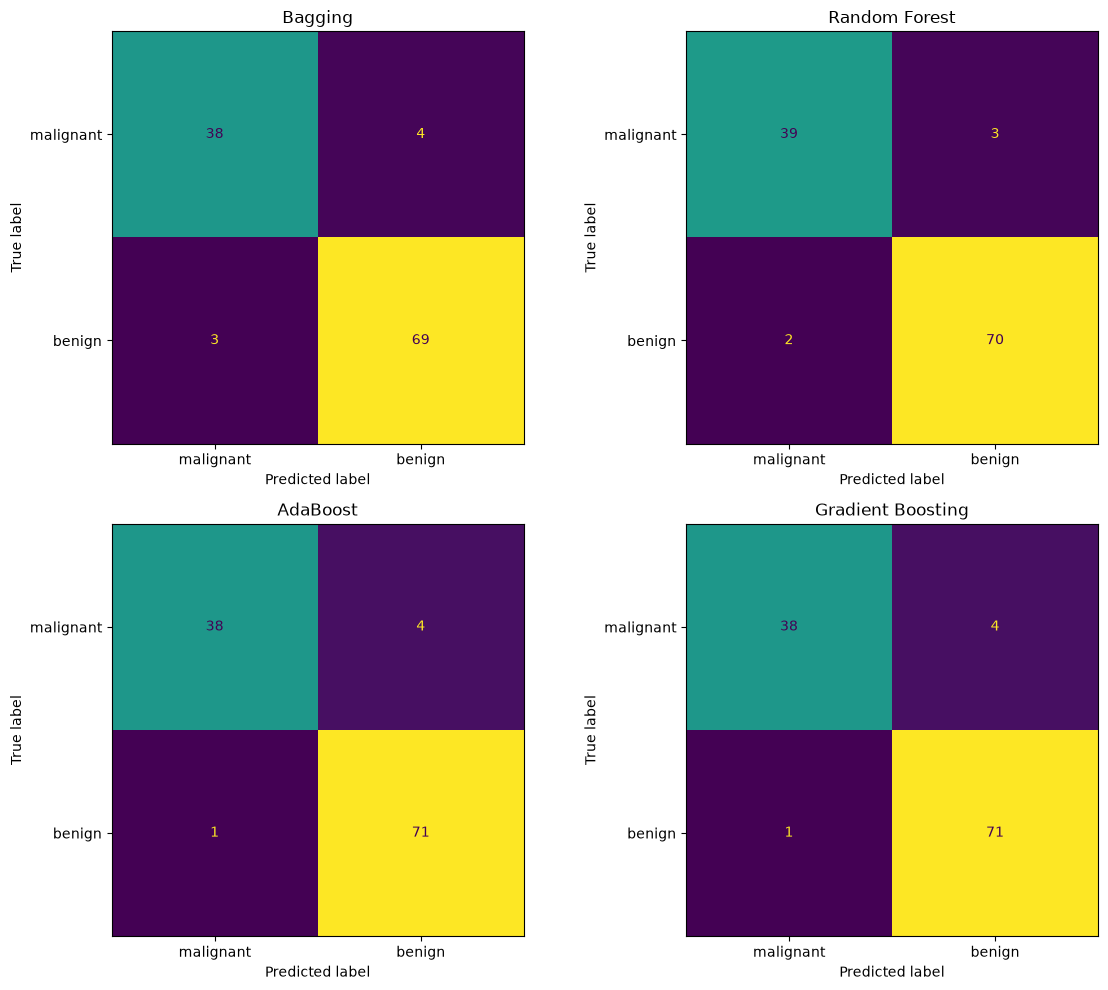

In [15]:
# Because this is a medical classification dataset(Breast Cancer Wisconsin), confusion matrices help us see how many malignant cases are incorrectly classified as benign.
# Compare confusion matrices for all ensemble classifiers

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for (name, model), ax in zip(
    ensemble_fitted_models.items(),
    axes.flatten()
):
    ConfusionMatrixDisplay.from_estimator(
        model,
        X_test,
        y_test,
        display_labels=cancer.target_names,
        ax=ax,
        colorbar=False
    )

    ax.set_title(name)

plt.tight_layout()
plt.show()


### Inference

Bagging, Random Forest, AdaBoost and Gradient Boosting were implemented and evaluated on the Breast Cancer Wisconsin dataset. Random Forest, AdaBoost and Gradient Boosting achieved the highest accuracy of 95.6% and an F1-score of 0.966, while Bagging achieved an accuracy of 93.9%. Random Forest obtained the highest ROC-AUC of 0.994, indicating strong class discrimination.

From the confusion matrices, Random Forest correctly classified 39 malignant and 70 benign cases, misclassifying only three malignant and two benign cases. AdaBoost and Gradient Boosting also performed well, correctly identifying 38 malignant and 71 benign cases each. Overall, Random Forest provided the best balance of classification performance in this experiment, while all three boosting and Random Forest models performed better than Bagging in terms of accuracy.


## Q2(c): Gaussian Mixture Model (GMM)

### Aim
To implement Gaussian Mixture Model clustering on the Iris dataset and evaluate the resulting clusters.

### Theory
A Gaussian Mixture Model is a probabilistic clustering algorithm that assumes the data is generated from a mixture of several Gaussian distributions. Each distribution represents a cluster.

Unlike K-means, which assigns each observation to its nearest centroid, GMM estimates the probability that an observation belongs to each cluster. It uses the Expectation-Maximization (EM) algorithm to estimate the parameters of the Gaussian distributions.

The silhouette score is used to evaluate cluster separation. A higher silhouette score generally indicates better-defined clusters.

### Methodology
1. Apply GMM to the standardized Iris dataset.
2. Use three components to represent three clusters.
3. Assign each observation to the cluster with the highest probability.
4. Evaluate the clusters using the silhouette score.
5. Visualize the clusters using two features.


In [ ]:
# This code implements Gaussian Mixture Model (GMM) clustering on the scaled iris dataset. 
# GMM is a probabilistic model that assumes the data is generated from a mixture of several Gaussian distributions. 
# The code fits the GMM to the data, predicts cluster labels, and evaluates the clustering performance using silhouette score. 
# It also prints the number of clusters, silhouette score, convergence status, and number of iterations taken by the algorithm.
# Convergence status indicates whether the algorithm has successfully converged to a solution, and the number of iterations shows how many iterations were performed during the fitting process.

# Q2(c): Gaussian Mixture Model clustering

gmm = GaussianMixture(
    n_components=3,
    random_state=RANDOM_STATE,
    n_init=5
)

gmm_labels = gmm.fit_predict(X_iris_scaled)

gmm_silhouette = silhouette_score(X_iris_scaled, gmm_labels)

print("Number of clusters:", len(np.unique(gmm_labels)))
print("Silhouette Score:", round(gmm_silhouette, 3))
print("Converged:", gmm.converged_)
print("Iterations:", gmm.n_iter_)


Number of clusters: 3
Silhouette Score: 0.374
Converged: True
Iterations: 19


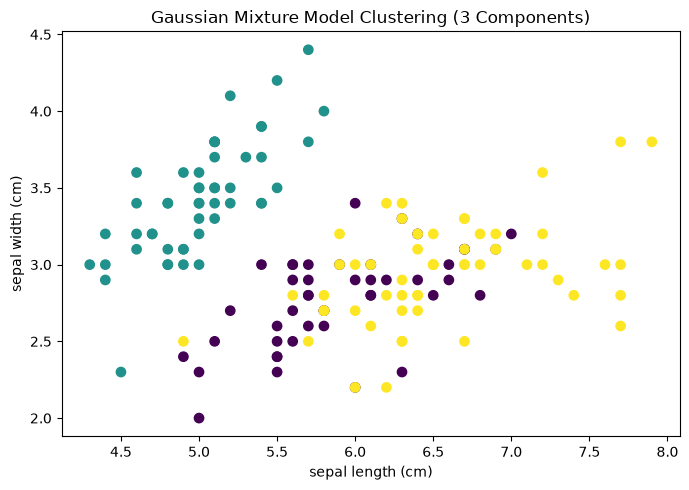

In [ ]:
# Here The First 2 Features of the Iris dataset are used to visualize the clusters formed by the Gaussian Mixture Model (GMM).

# The first two features of the Iris dataset are used for visualization because they allow us to create a 2D scatter plot, which is easier to interpret and visualize.

# Visualize GMM clusters using the first two Iris features

plt.figure(figsize=(7, 5))

plt.scatter(
    X_iris.iloc[:, 0],
    X_iris.iloc[:, 1],
    c=gmm_labels,
    s=45
)

plt.xlabel(iris.feature_names[0])
plt.ylabel(iris.feature_names[1])
plt.title("Gaussian Mixture Model Clustering (3 Components)")
plt.tight_layout()
plt.show()


Inference

The Gaussian Mixture Model was applied to the standardized Iris dataset using three components. The model converged successfully after 19 iterations and formed three clusters, achieving a silhouette score of 0.374. The scatter plot shows that one cluster is relatively well separated, while the other two overlap in some regions. This indicates that the clusters are not completely distinct. Unlike K-means, GMM uses probability distributions to assign observations to clusters, allowing it to capture different cluster shapes and spreads.


## Q2(d): Principal Component Analysis (PCA)

### Aim
To apply Principal Component Analysis to reduce the dimensionality of the Iris dataset and visualize the data using principal components.

### Theory
Principal Component Analysis (PCA) is a dimensionality reduction technique that transforms the original features into a smaller set of new features called principal components.

The first principal component captures the maximum possible variance in the data. Each subsequent component captures as much of the remaining variance as possible while remaining orthogonal to the previous components.

PCA helps reduce the number of features, simplify data visualization and remove some redundancy while retaining important information.

### Methodology
1. Standardize the Iris dataset.
2. Apply PCA to reduce the four original features to two principal components.
3. Calculate the explained variance ratio and cumulative explained variance.
4. Visualize the transformed observations.
5. Interpret how much information is retained after dimensionality reduction.


In [18]:
# Here we are applying Principal Component Analysis (PCA) to reduce the dimensionality of the iris dataset from four features to two principal components. 
# PCA is a technique used to emphasize variation and capture strong patterns in a dataset. 
# It helps in reducing the number of dimensions while retaining most of the information.
# Q2(d): Apply PCA to reduce four features to two components

pca = PCA(n_components=2)

X_iris_pca = pca.fit_transform(X_iris_scaled)

explained_variance = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

pca_results_df = pd.DataFrame({
    "Principal Component": ["PC1", "PC2"],
    "Explained Variance Ratio": explained_variance,
    "Cumulative Explained Variance": cumulative_variance
})

display(pca_results_df.round(4))

print(
    "Total variance retained:",
    round(cumulative_variance[-1] * 100, 2),
    "%"
)


,Principal Component,Explained Variance Ratio,Cumulative Explained Variance
0,PC1,0.7296,0.7296
1,PC2,0.2285,0.9581


Total variance retained: 95.81 %


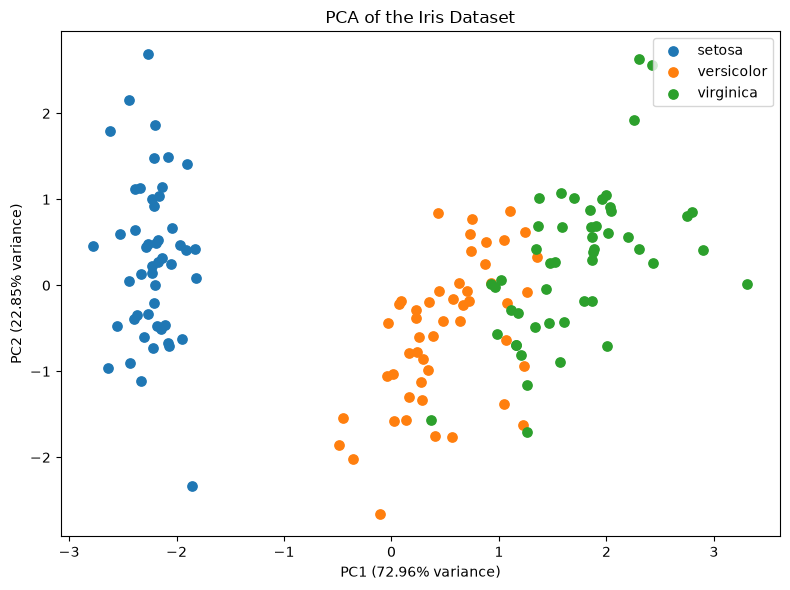

In [19]:
# Here we are visualizing the PCA results by plotting the first two principal components of the iris dataset.
# Visualize Iris observations using the first two principal components

plt.figure(figsize=(8, 6))

for class_id, class_name in enumerate(iris.target_names):
    plt.scatter(
        X_iris_pca[y_iris == class_id, 0],
        X_iris_pca[y_iris == class_id, 1],
        label=class_name,
        s=45
    )

plt.xlabel(
    f"PC1 ({explained_variance[0] * 100:.2f}% variance)"
)
plt.ylabel(
    f"PC2 ({explained_variance[1] * 100:.2f}% variance)"
)
plt.title("PCA of the Iris Dataset")
plt.legend()
plt.tight_layout()
plt.show()


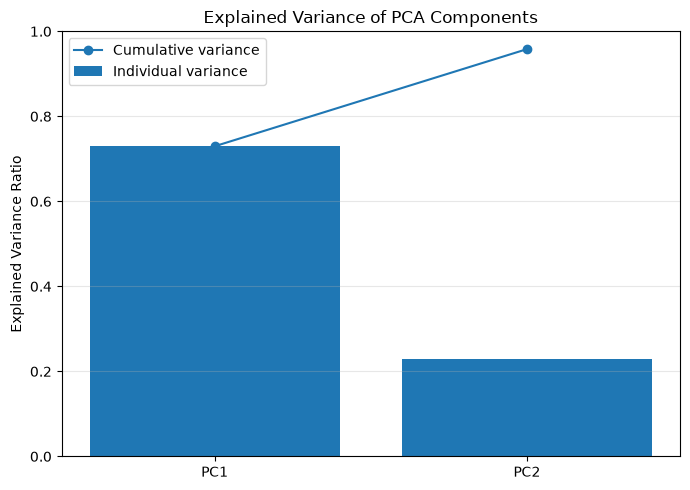

In [ ]:
# A plot of the explained variance of the principal components is created to visualize how much variance each principal component captures from the original dataset.
# Plot the explained variance of the principal components

plt.figure(figsize=(7, 5))

plt.bar(
    ["PC1", "PC2"],
    explained_variance,
    label="Individual variance"
)

plt.plot(
    ["PC1", "PC2"],
    cumulative_variance,
    marker="o",
    label="Cumulative variance"
)

plt.ylabel("Explained Variance Ratio")
plt.title("Explained Variance of PCA Components")
plt.ylim(0, 1)
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


### Inference

PCA was applied to the standardized Iris dataset to reduce its four original features to two principal components. The first principal component (PC1) explained 72.96% of the total variance, while the second component (PC2) explained 22.85%. Together, they retained 95.81% of the total variance. The scatter plot shows that Setosa is clearly separated from the other two species, whereas Versicolor and Virginica have some overlap. Thus, PCA reduced the dimensionality of the dataset while preserving most of its information, making the data easier to visualize and analyze.


# Q3: Performance Analysis

## 6.1 Aim
To analyze the performance of the implemented clustering, ensemble learning and dimensionality reduction techniques using appropriate evaluation metrics.

## 6.2 Summary of Analysis of Metrics Using Appropriate Metrics for Algorithms

The clustering algorithms were evaluated using silhouette scores, which measure how well observations fit within their assigned clusters compared with other clusters. The K-means and Hierarchical Clustering experiments showed that cluster quality varies with the number of clusters and the linkage method. The Gaussian Mixture Model provided probabilistic clustering and achieved a silhouette score of 0.374.

For ensemble classification, accuracy, precision, recall, F1-score and ROC-AUC were used to compare Bagging, Random Forest, AdaBoost and Gradient Boosting. Random Forest, AdaBoost and Gradient Boosting achieved an accuracy of 95.6%, while Random Forest obtained the highest ROC-AUC of 0.994.

PCA reduced the four original Iris features to two principal components while retaining 95.81% of the total variance. The visualization showed clear separation of Setosa, although some overlap remained between Versicolor and Virginica.



## 6.3 Conclusion

In this experiment, different unsupervised learning, ensemble learning and dimensionality reduction techniques were implemented and evaluated. K-means and Hierarchical Clustering demonstrated how distance measures and linkage methods influence cluster formation. GMM provided a probabilistic approach to clustering. Among the ensemble classifiers, Random Forest achieved strong overall performance, with 95.6% accuracy and a ROC-AUC of 0.994. PCA reduced the dataset to two components while preserving 95.81% of its variance. Overall, the experiment demonstrated the applications and performance differences of these machine learning techniques.
